In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os
from pathlib import Path
from PIL import Image

In [2]:
#baca dataset
dataset_dir = Path("../dataset")

print(dataset_dir.exists())

True


In [3]:
#identifikasi kelas 
classes = [folder.name for folder in dataset_dir.iterdir()
           if folder.is_dir()]

print("Jumlah kelas:", len(classes))
print("Nama kelas:", classes)

Jumlah kelas: 1
Nama kelas: ['flowers']


In [4]:
# Menghitung jumlah gambar setiap kelas

class_counts = {}

for class_name in classes:

    folder = dataset_dir / class_name

    images = [
        file for file in folder.iterdir()
        if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    class_counts[class_name] = len(images)

print(class_counts)

{'flowers': 0}


In [5]:
#distribusi jumlah gambar perkelas

df_distribution = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Total Images"]
)

print(df_distribution)

     Class  Total Images
0  flowers             0


In [6]:
#cek duplikat 
import hashlib

image_hashes = {}

for class_name in classes:
    folder = dataset_dir / class_name

    for img_path in folder.iterdir():

        if img_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:

            with open(img_path, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()

            image_hashes.setdefault(file_hash, []).append({
                "class": class_name,
                "file": img_path
            })

#cek jumlah
duplicates = {
    hash_value: files
    for hash_value, files in image_hashes.items()
    if len(files) > 1
}

print("Jumlah grup duplikasi:", len(duplicates))
print()



Jumlah grup duplikasi: 0



In [7]:
#hapus duplikasi
for hash_value, files in duplicates.items():

    # Mempertahankan gambar pertama
    for duplicate_file in files[1:]:

        duplicate_file["file"].unlink()

print("Duplikasi berhasil dibersihkan!")

Duplikasi berhasil dibersihkan!


In [8]:
# Menghitung jumlah gambar setiap kelas

class_counts = {}

for class_name in classes:

    folder = dataset_dir / class_name

    images = [
        file for file in folder.iterdir()
        if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    class_counts[class_name] = len(images)


df_after_drop = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Total Images"]
)

print(df_after_drop)

     Class  Total Images
0  flowers             0


# Melihat distribusi

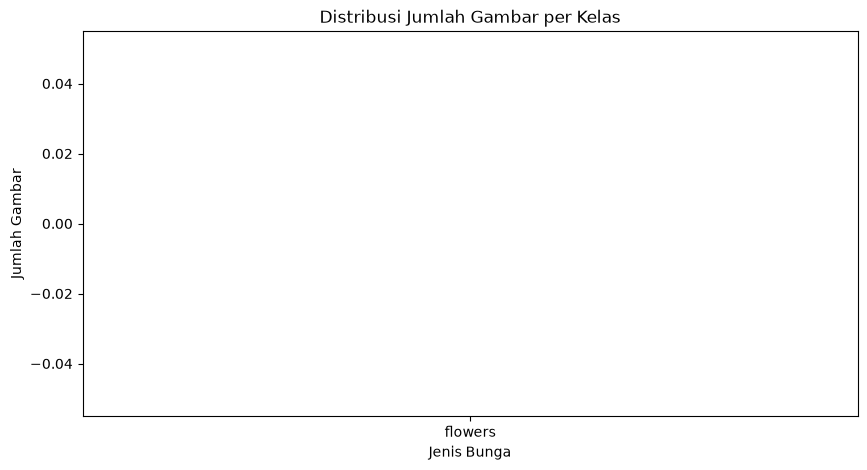

In [9]:
# Distribusi jumlah gambar setiap kelas

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_distribution,
    x="Class",
    y="Total Images"
)

plt.title("Distribusi Jumlah Gambar per Kelas")
plt.xlabel("Jenis Bunga")
plt.ylabel("Jumlah Gambar")

plt.show()

Analisis:
1. Kelas Dandelion memiliki jumlah gambar terbanyak, yaitu sekitar 1.050 gambar.
2. Kelas Sunflower memiliki jumlah gambar paling sedikit, yaitu sekitar 730 gambar.
3. Kelas Tulip memiliki jumlah gambar yang relatif tinggi, mendekati 1.000 gambar.
4. Daisy dan Rose memiliki jumlah gambar yang relatif berdekatan.
5. Terdapat perbedaan jumlah sampel antara kelas dengan jumlah tertinggi dan terendah.

In [10]:
# Distribusi persentase setiap kelas

df_distribution["Percentage"] = (
    df_distribution["Total Images"] /
    df_distribution["Total Images"].sum()
) * 100

print(df_distribution)

     Class  Total Images  Percentage
0  flowers             0         NaN


- Dandelion memiliki proporsi terbesar (24,37%).


- Sunflower memiliki proporsi terkecil (16,98%).


- Distribusi antarkelas relatif merata.

In [11]:
#mengukur seberapa besar perbedaan distribusinya.(balance/imbalance)
max_images = df_distribution["Total Images"].max()
min_images = df_distribution["Total Images"].min()

ratio = max_images / min_images

print("Jumlah terbanyak:", max_images)
print("Jumlah tersedikit:", min_images)
print("Rasio:", round(ratio, 2))

Jumlah terbanyak: 0
Jumlah tersedikit: 0
Rasio: nan


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13344\3648029463.py:5: RuntimeWarning: invalid value encountered in scalar divide
  ratio = max_images / min_images


- Jumlah gambar Dandelion lebih banyak daripada kelas lain


- Sunflower merupakan kelas dengan jumlah gambar paling sedikit.


- Rasio 1,44 menunjukkan perbedaan jumlah sampel tidak terlalu ekstrem.


- Dataset memiliki sedikit ketidakseimbangan distribusi, tetapi belum menunjukkan ketimpangan yang besar.

PermissionError: [Errno 13] Permission denied: '..\\dataset\\flowers\\daisy'

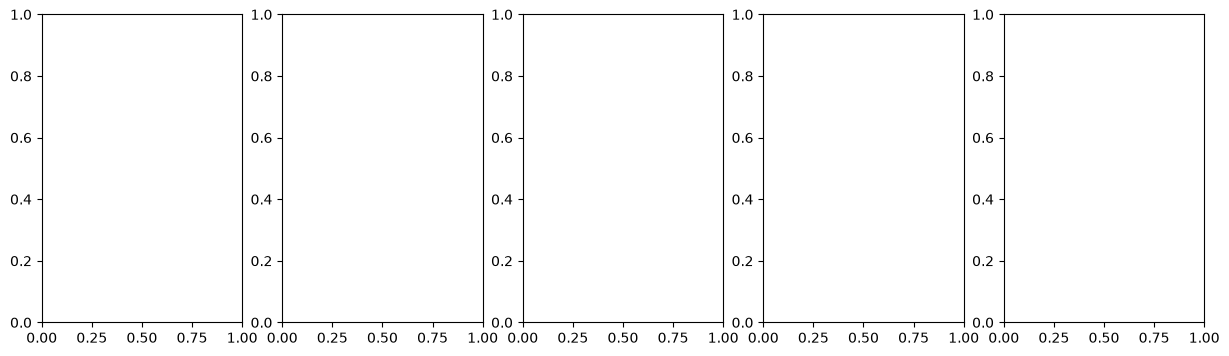

In [12]:
# Visualisasi sampel gambar setiap kelas

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i, class_name in enumerate(classes):

    folder = dataset_dir / class_name

    images = list(folder.glob("*"))

    img = Image.open(images[0])

    axes[i].imshow(img)
    axes[i].set_title(class_name)
    axes[i].axis("off")

plt.tight_layout()
plt.show()


Daisy

Kelopak berwarna putih dengan bagian tengah kuning.


Dandelion

Memiliki struktur bunga berbentuk bulat dengan banyak bagian kecil.


Rose	

Memiliki kelopak bertumpuk dengan bentuk yang lebih kompleks.


Sunflower	

Memiliki warna kuning mencolok dan bagian tengah yang relatif besar.


Tulip	

Memiliki kelopak berbentuk memanjang dan cenderung tertutup.